# Steel Beam
**AISC 360-22 (LRFD or ASD) · ASCE 7-22 load combinations · IBC 2024 deflection limits**

Single-span, cantilever, overhang, fixed-end, or continuous beam with a W or HSS section.
Checks flexure (yielding, lateral-torsional buckling with Cb from the moment diagram,
and local buckling), shear, and service deflection, with optional auto-selection of the lightest W shape.

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`).

> Design aid only. A licensed engineer must verify all inputs and results.

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_476d0793fd")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build 476d0793fd)")

structcalc 0.1.0 ready (build 476d0793fd)


In [2]:
#@title 1. Section and material
section = "W18X35"  #@param {type:"string"}
Fy = 50.0  #@param {type:"number"}
method = "LRFD"  #@param ["LRFD", "ASD"]
auto_select = False  #@param {type:"boolean"}
depth_filter = ""  #@param ["", "8", "10", "12", "14", "16", "18", "21", "24", "27", "30", "33", "36"]
#@markdown Section examples: `W18X35`, `HSS8X4X1/4`, `HSS6.625X0.280`.
#@markdown With *auto_select*, the lightest passing W shape is chosen (optionally limited to one nominal depth).

In [3]:
#@title 2. Geometry and bracing
span_type = "Simple span"  #@param ["Simple span", "Cantilever", "Overhang one end (right)", "Overhang both ends", "Fixed-fixed", "Fixed-pinned (propped)", "Custom supports"]
span = 24.0  #@param {type:"number"}
overhang_left = 0.0  #@param {type:"number"}
overhang_right = 0.0  #@param {type:"number"}
custom_supports = "0:pin, 20:pin, 40:pin"  #@param {type:"string"}
bracing = "At interval"  #@param ["Continuous (both flanges)", "Top flange continuous", "At supports only", "At interval"]
brace_interval = 8.0  #@param {type:"number"}
#@markdown Lengths in **ft**. *custom_supports* applies only when *span_type* is **Custom supports** (`x:pin` or `x:fixed`).

In [4]:
#@title 3. Loads (service level, + down)
#@markdown Full-length uniform loads in **plf**:
w_D = 400.0  #@param {type:"number"}
w_L = 800.0  #@param {type:"number"}
w_Lr = 0.0  #@param {type:"number"}
w_S = 0.0  #@param {type:"number"}
w_W = 0.0  #@param {type:"number"}
self_weight = True  #@param {type:"boolean"}
#@markdown Extra loads (separate with `;`): `P, x, kip, case` · `w, x1, x2, kip/ft, case` · `t, x1, x2, w1, w2, case` · `M, x, kip-ft, case`
extra_loads = "P, 12, 5.0, L"  #@param {type:"string"}
live_defl_limit = 360  #@param {type:"integer"}
total_defl_limit = 240  #@param {type:"integer"}

In [5]:
#@title 4. Calculate
from structcalc.calcs import steel_beam

out = steel_beam.run(
    section=section, auto_select=auto_select, depth_filter=depth_filter,
    Fy=Fy, method=method, span_type=span_type, span=span,
    overhang_left=overhang_left, overhang_right=overhang_right,
    custom_supports=custom_supports,
    w={"D": w_D / 1000, "L": w_L / 1000, "Lr": w_Lr / 1000, "S": w_S / 1000, "W": w_W / 1000},
    extra_loads=extra_loads, self_weight=self_weight,
    bracing=bracing, brace_interval=brace_interval,
    live_defl=live_defl_limit, total_defl=total_defl_limit,
)
out["report"].show()

Section,W18X35,
Fy,50,ksi
E,"29,000",ksi
Span type,Simple span,
Total length,24,ft
Supports,"0 ft pin, 24 ft pin",
Uniform load D,400,plf
Uniform load L,800,plf
Extra loads,"P, 12, 5.0, L",
Self weight included,Yes,
Bracing,At interval @ 8 ft,


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


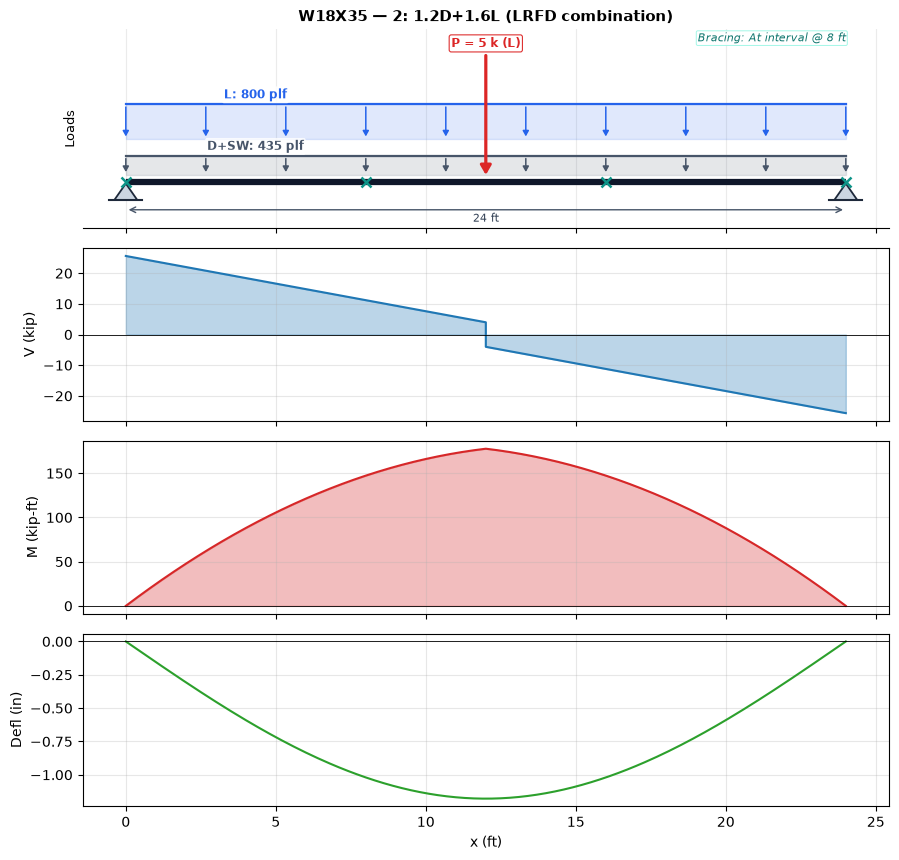

In [6]:
#@title 5. Loads and diagrams (governing flexure combination)
from structcalc.beam import plot

name, seg, res = out["governing"]["flex"]
fig = plot(res, title=f"{out['section']['name']} — {name} ({method} combination)",
           beam=out["beam"], brace_pts=out["brace_pts"], bracing_note=out["bracing_note"])

In [7]:
#@title 6. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html(f"steel_beam_{out['section']['name']}.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass